<a href="https://colab.research.google.com/github/yamangakre2007-afks/Carrermate-AI/blob/main/project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

I just took a little help from Claude AI.

In [1]:
import random
import matplotlib.pyplot as plt

SIMULATION_TIME = 600
ARRIVAL_CHANCE = {
    "N": 0.30,
    "S": 0.30,
    "E": 0.15,
    "W": 0.15,
}
FIXED_GREEN_TIME = 20
MIN_GREEN_TIME = 8
CARS_PASSING_PER_SEC = 1
SEED = 42

In [2]:
class Intersection:
    def __init__(self, mode):
        self.mode = mode
        self.queues = {d: [] for d in "NSEW"}
        self.green = "NS"
        self.time_in_green = 0
        self.total_wait = 0
        self.cars_passed = 0
        self.max_queue = 0
        self.history = []

    def add_cars(self, now):
        for road, chance in ARRIVAL_CHANCE.items():
            if random.random() < chance:
                self.queues[road].append(now)

    def switch_light(self):
        self.green = "EW" if self.green == "NS" else "NS"
        self.time_in_green = 0

    def update_light(self):
        self.time_in_green += 1

        if self.mode == "fixed":
            if self.time_in_green >= FIXED_GREEN_TIME:
                self.switch_light()
        else:
            if self.time_in_green < MIN_GREEN_TIME:
                return
            ns = len(self.queues["N"]) + len(self.queues["S"])
            ew = len(self.queues["E"]) + len(self.queues["W"])
            green_cars = ns if self.green == "NS" else ew
            red_cars = ew if self.green == "NS" else ns
            if red_cars > green_cars:
                self.switch_light()

    def move_cars(self, now):
        for road in self.green:
            for _ in range(CARS_PASSING_PER_SEC):
                if self.queues[road]:
                    arrival = self.queues[road].pop(0)
                    self.total_wait += now - arrival
                    self.cars_passed += 1

    def step(self, now):
        self.add_cars(now)
        self.move_cars(now)
        self.update_light()
        waiting = sum(len(q) for q in self.queues.values())
        self.history.append(waiting)
        self.max_queue = max(self.max_queue, max(len(q) for q in self.queues.values()))

    def report(self):
        waiting = sum(len(q) for q in self.queues.values())
        avg_wait = self.total_wait / self.cars_passed if self.cars_passed else 0
        return {
            "Cars passed": self.cars_passed,
            "Cars still waiting": waiting,
            "Average wait (sec)": round(avg_wait, 1),
            "Longest queue": self.max_queue,
        }

In [3]:
def run(mode):
    random.seed(SEED)
    city = Intersection(mode)
    for second in range(SIMULATION_TIME):
        city.step(second)
    return city

In [4]:
fixed_city = run("fixed")
smart_city = run("smart")

fixed = fixed_city.report()
smart = smart_city.report()

print(f"{'Result':<22}{'Fixed light':>14}{'Smart light':>14}")
print("-" * 50)
for key in fixed:
    print(f"{key:<22}{fixed[key]:>14}{smart[key]:>14}")

improvement = (1 - smart["Average wait (sec)"] / fixed["Average wait (sec)"]) * 100
print(f"\nSmart light cut the average waiting time by {improvement:.0f}%.")

Result                   Fixed light   Smart light
--------------------------------------------------
Cars passed                      510           517
Cars still waiting                 7             0
Average wait (sec)               7.3           2.9
Longest queue                     10             5

Smart light cut the average waiting time by 60%.


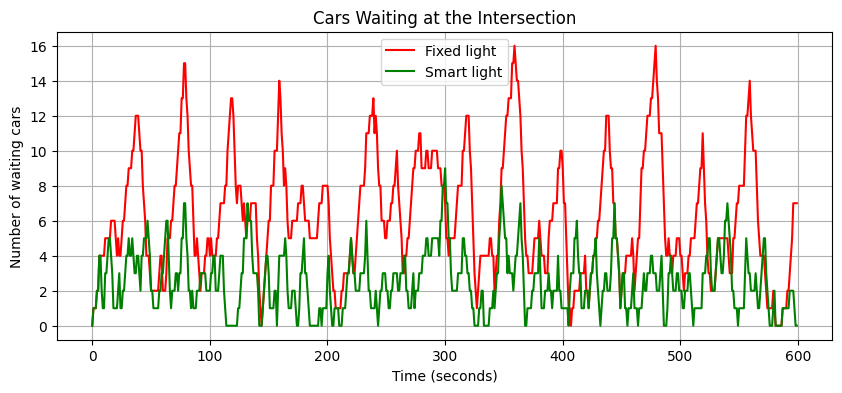

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(fixed_city.history, label="Fixed light", color="red")
plt.plot(smart_city.history, label="Smart light", color="green")
plt.title("Cars Waiting at the Intersection")
plt.xlabel("Time (seconds)")
plt.ylabel("Number of waiting cars")
plt.legend()
plt.grid(True)
plt.show()

In [6]:

ARRIVAL_CHANCE = {"N": 0.45, "S": 0.45, "E": 0.30, "W": 0.30}